<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/6%EC%A3%BC%EC%B0%A8/10_12_mnist_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

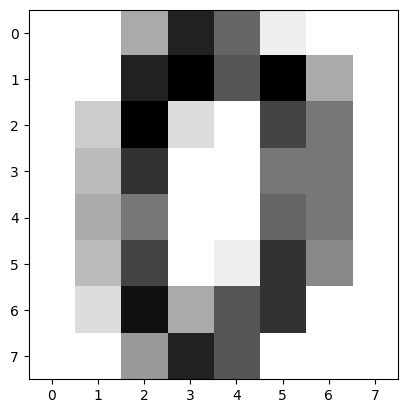

In [11]:
# Mnist 분류
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import tensorflow as tf
import pandas as pd


# 8x8 손글씨 숫자 이미지 데이터 불러오기
digits = datasets.load_digits()
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

# 8x8 이미지를 64개 값이 한 줄로 늘어선 형태로 펼치기
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# y 데이터인 digits.target 을 원-핫 인코딩 하기
# 근데 원-핫 인코딩 안하고 그대로 쓸거면 손실 함수가 달라지겠지
Y=pd.get_dummies(digits.target).values


In [12]:
# 3. 데이터 구조 확인
print("이미지 배열 크기:", digits.images.shape)   # (1797, 8, 8)
print("펼친 데이터 크기:", data.shape)            # (1797, 64)
print("라벨 크기:", digits.target.shape)
print("픽셀 값 범위:", data.min(), "~", data.max())  # 0 ~ 16
print("결측치 개수:", np.isnan(data).sum())

print("\n클래스별 개수")
print(pd.Series(digits.target).value_counts().sort_index())

이미지 배열 크기: (1797, 8, 8)
펼친 데이터 크기: (1797, 64)
라벨 크기: (1797,)
픽셀 값 범위: 0.0 ~ 16.0
결측치 개수: 0

클래스별 개수
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


In [13]:
# 4.결측치 와 중복 데이터 확인
print("전체 결측치 개수:", np.isnan(data).sum())
print("중복 이미지 수:", len(data) - len(np.unique(data, axis=0)))

전체 결측치 개수: 0
중복 이미지 수: 0


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,778 (10.85 KB)

 Trainable params: 2,778 (10.85 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2089 - loss: 2.2608 - val_accuracy: 0.3681 - val_loss: 2.1612
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3925 - loss: 2.0426 - val_accuracy: 0.3750 - val_loss: 1.9324
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4578 - loss: 1.7504 - val_accuracy: 0.4653 - val_loss: 1.6307
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6084 - loss: 1.4369 - val_accuracy: 0.6736 - val_loss: 1.3255
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7502 - loss: 1.1466 - val_accuracy: 0.7396 - val_loss: 1.0560
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8242 - loss: 0.8999 - val_accuracy: 0.8090 - val_loss: 0.8440
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8625 - loss: 0.7203 - val_accuracy: 0.8194 - val_loss: 0.7097
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8834 - loss: 0.5958 - val_accuracy: 0.8507

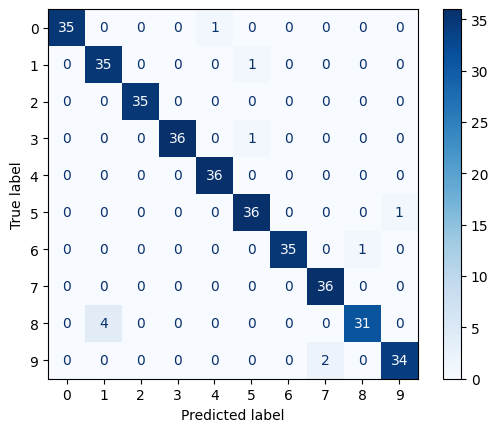

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    data /16.0, Y, test_size=0.2, random_state=42 , stratify=digits.target)

# 64 개의 값이 한 줄로 되어 있으면 입력층이 64가 된다
# 이 Mnist 는 다중 분류 + 단일 레이블 이기 때문에 출력층을 softmax 를 사용하고 전체 레이블이 10개가 있기 때문에
# 출력층의 노드도 10개가 된다
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax"),
])


# 7. 모델 설정 (한 번만)
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

# 8. 모델 구조 출력
model.summary()



# 9. 모델 학습 (검증 손실이 10 에포크 동안 좋아지지 않으면 멈추고 최적 가중치로 복원)
# EarlyStopping은 val_loss 하나만 지켜보고 한 애폭 동안 가장 작은 손실을 내면 그 가중치를 기억해 두고
# 그 이후로 10 애폭 동안 손실이 최적일 때 보다 낮아지지 않으면 중단하고 해당 가중치로 되돌리고 학습을 중단함

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

# 에포크마다의 손실과 정확도를 기록해 둔 것
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early],
    verbose=1,
)


# 지금 이 모델에서 마지막 출력층의 활성화 함수가 softmax 이다.
# 즉 , 출력층의 노드가 총 10개 이므로 결과가 다음과 같은 식으로 나온다
# [0.01, 0.00, 0.02, 0.90, 0.01, 0.03, 0.00, 0.01, 0.01, 0.01] 이런식으로 모든 확률값의 합이 1이 된다
# 근데 이 중에 우리는 제일 큰 값인 3번 칸을 골라내야한다
# 지금 Y 자체가 원핫 인코딩이 되어 있기 때문에 y_test 도 원핫 인코딩 되어 있는 [0, 0, 0, 1, 0, 0, 0, 0, 0, 0] 이런식
# 근데 accuracy_score 로 예측한 값과 정답을 비교하기 위해서 둘다 np.argmax 를 통해서 정수 값으로 바꾼다
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))
print()
print(classification_report(y_true, y_pred))

# 혼동행렬로 확인
# 결과상 8이라는 이미지의 사진을 1로 잘못 판단하는 경우가 4번이나 있었음

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred)).plot(cmap="Blues")